# DCD trajectory analysis & 3D viewer (Colab)

Driver notebook for `modules/trajectory_viewer.py` **v1.4.0** + `modules/evidence_cutoff.py` (mdtraj + MDAnalysis + py3Dmol).
Input: the files written by the OpenMM+CHARMM cell of the pipeline notebook
(`OPENMM_SAVE_DCD = True`, scoring module **v1.2.0+**):

```
AF3_HADDOCK/projects/<DATASET>/
├── work/5_openmm/results/<prediction_id>.json        status + run settings (contract)
├── work/5_openmm/trajectories/<prediction_id>.dcd
├── work/5_openmm/pdb/<prediction_id>_minimized.pdb   topology of the DCD
├── work/5_openmm/results/em_openmm_merged.csv        scores for the selection
└── outputs/viewer/  outputs/trajectories/            written here (kept)
PBI_WGS_preprocess/results/cross/**/ *cross_pairs*.json   names/sequences/annotation (section 10)
```
Paths come from `pipeline_layout.py`; set the same `DATASET` as in the pipeline
notebook (or leave `None` when there is only one project folder). The last sections write
`outputs/viewer/final_candidates_annotated.csv` (name, sequence and annotation of
the bacterial OMP and the phage RBP of every selected candidate), copy the
selected trajectories to `outputs/trajectories/` and remove the intermediates (`work/`).

Trajectories are discovered from the per-sample result JSONs: only runs with
status PASS are used, and the frame layout (minimization frame, MD report
interval) is read from each run — nothing has to be copied from the pipeline
notebook by hand.

DCD frames: **0 = initial, 1 = minimized, 2+ = MD**. With `OPENMM_MD_STEPS = 0`
there are only 2 frames, so time-series plots are short and RMSF is not available.

## 0. Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q mdanalysis mdtraj py3Dmol matplotlib pandas scipy

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Config

In [ ]:
import os
import sys
import importlib
from pathlib import Path

DRIVE      = Path(os.environ.get("AF3_DRIVE_ROOT", "/content/drive/MyDrive"))
MODULE_DIR = DRIVE / "AF3_HADDOCK" / "modules"
if str(MODULE_DIR) not in sys.path:
    sys.path.insert(0, str(MODULE_DIR))

import pipeline_layout as pl
importlib.reload(pl)

# --- project folder (same as in the pipeline notebook) ------------------------
DATASET     = None       # None: the only folder in AF3_HADDOCK/projects/ | or e.g. "ST307"
PROJECT_DIR = None       # optional: full path of the project folder

_project = pl.resolve_project(DRIVE, DATASET, PROJECT_DIR)
L = pl.make_layout(DRIVE, _project.name, project_dir=_project)
DATASET = L.dataset

OPENMM_ROOT  = L.openmm_dir
RESULTS_DIR  = OPENMM_ROOT / "results"
TRAJ_DIR     = OPENMM_ROOT / "trajectories"
PDB_DIR      = OPENMM_ROOT / "pdb"
MERGED_CSV   = RESULTS_DIR / "em_openmm_merged.csv"
ANALYSIS_DIR = L.outputs_viewer              # kept after cleanup

# --- which trajectories --------------------------------------------------
# Kneedle cutoff per score (smaller is better), computed independently on all
# usable trajectories; a sample is selected only if it passes ALL cutoffs (AND).
SELECT_COLUMNS = [
    "initial_potential_kj_mol",
    "haddock_score",
    "minimized_potential_kj_mol",
]
KNEEDLE_TRANSFORM    = {}      # e.g. {"haddock_score": None}; values must be >= 0 for "log1p"
KNEEDLE_MIN_POINTS   = 10      # fewer values -> 95th-percentile gap fallback
KNEEDLE_MIN_DISTANCE = 0.05    # almost straight sorted curve -> fallback
BOOTSTRAP_N          = 200     # cutoff stability report (0 = off)
ORDER_BY             = "minimized_potential_kj_mol"   # order of the selected list
GRID_MAX             = 20      # at most this many structures in the comparison grid
VIEW_ID = None                 # prediction_id to inspect; None -> rank 1

# --- analysis / view ------------------------------------------------------
STRIDE                 = 1     # use every n-th frame (labels keep the original frame index)
CONTACT_CUTOFF_A       = 4.5   # heavy-atom contact cutoff for the per-frame metrics
INTERFACE_CUTOFF_A     = 0.5   # interface residues shown as sticks
COMPUTE_BSA            = True  # Shrake-Rupley; slow for very large complexes
ANIMATION_INTERVAL_MS  = 200
GRID_COLUMNS           = 5

if str(MODULE_DIR) not in sys.path:
    sys.path.insert(0, str(MODULE_DIR))

import matplotlib.pyplot as plt
import pandas as pd
import trajectory_viewer as tv
importlib.reload(tv)

print("trajectory_viewer", tv.MODULE_VERSION)
if not tv.MODULE_VERSION.startswith(("1.4", "1.5")):
    raise RuntimeError("trajectory_viewer.py v1.4.0+ is required (select_kneedle_and).")
print("pipeline_layout", pl.MODULE_VERSION, "| dataset", DATASET)
print("Results      :", RESULTS_DIR, "| exists:", RESULTS_DIR.is_dir())
print("Analysis out :", ANALYSIS_DIR)
if pl.stage_done(L, "cleanup"):
    raise RuntimeError(
        "The intermediates of this dataset were already removed (cleanup). "
        f"Final files are in {L.outputs_dir}; re-run the pipeline notebook to view trajectories again."
    )
if not pl.stage_done(L, "pipeline"):
    print("NOTE: the pipeline notebook has not marked its stage done yet "
          "(run its '10. Finalize' cell before cleanup).")

## 2. Discover trajectories and select samples (Kneedle cutoff per score, AND)

Reads `results/<id>.json`. A row is **usable** when the run passed, trajectory
output was on and both the DCD and its `_minimized.pdb` exist; the others are
listed with the reason (e.g. a failed MD run that left a partial DCD).
Scores are joined from `em_openmm_merged.csv`.

**Selection** on the usable trajectories:

1. Each score is handled **independently** on all usable trajectories:
   `initial_potential_kj_mol`, `haddock_score`, `minimized_potential_kj_mol`
   are each sorted ascending (smaller = better) and the **elbow** of the sorted
   curve is found with the Kneedle algorithm (same algorithm as the evidence
   cell of the pipeline, `evidence_cutoff.py`). Samples at least as good as the
   elbow value pass that score. Without an elbow the 95th-percentile gap rule is
   used and reported (`gap95_fallback`).
2. **AND**: only samples that pass all three cutoffs are selected. The number of
   selected samples is therefore not fixed.

Printed: per-score cutoff, pass counts, bootstrap stability of each cutoff,
overlap of the pass sets, and CSV samples that would pass but have no usable
trajectory. Saved: `analysis/selection_kneedle_and.csv` and `analysis/selection_cutoffs.csv`.

Frame layouts (minimized, report_interval, md_steps) -> runs:
minimized  report_interval  md_steps
True       1000             0           90

Kneedle cutoff per score (smaller is better)
                    column method_used   shape  cutoff_value  n_available  n_missing  n_pass    cutoff_p05    cutoff_p50    cutoff_p95  no_elbow_fraction
  initial_potential_kj_mol     kneedle concave  1.181509e+10           75         15      73  1.174004e+08  1.181509e+10  1.181509e+10                0.0
             haddock_score     kneedle  convex -1.543250e+02           75         15       9 -1.849380e+02 -1.543250e+02 -8.117480e+01                0.0
minimized_potential_kj_mol     kneedle  convex -6.367548e+04           75         15      27 -9.278129e+04 -6.367548e+04 -5.236158e+04                0.0

Pass-set overlap
  initial_potential_kj_mol AND haddock_score: 9
  initial_potential_kj_mol AND minimized_potential_kj_mol: 25
  haddock_score AND minimized_potential_kj_mol: 4
  ALL (3 scores): 

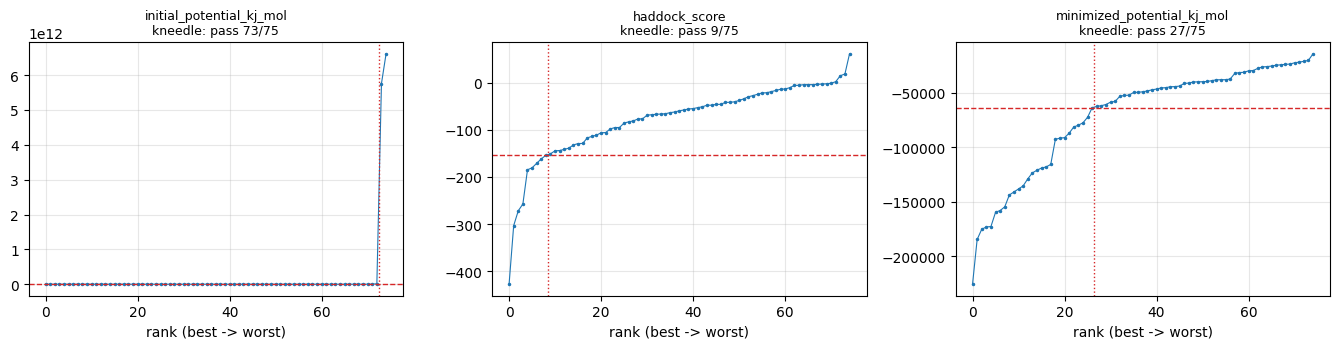


Usable trajectories: 90 | selected (AND): 4 -> /content/drive/MyDrive/MD_output_openmm/analysis/selection_kneedle_and.csv


,rank,prediction_id,initial_potential_kj_mol,haddock_score,minimized_potential_kj_mol,initial_potential_kj_mol_rank,haddock_score_rank,minimized_potential_kj_mol_rank
0,1,fold_140_deguysxt_cds_0008_hpiihm_03928,1.315814e+06,-303.274,-175352.706267,68,2,3
1,2,fold_195_deguysxt_cds_0009_hpiihm_04206,1.174004e+08,-271.803,-91560.750816,70,3,20
2,3,fold_191_deguysxt_cds_0009_hpiihm_03803,-3.945547e+04,-171.257,-87047.510645,8,7,22
3,4,fold_192_deguysxt_cds_0009_hpiihm_03928,-7.178891e+03,-427.484,-81406.148891,39,1,23


In [3]:
import numpy as np

all_runs = tv.discover_from_results(RESULTS_DIR, MERGED_CSV, TRAJ_DIR, PDB_DIR)

if all_runs.empty:
    raise RuntimeError(
        f"No result JSONs in {RESULTS_DIR}.\n"
        "Run the OpenMM cell of the pipeline notebook with OPENMM_SAVE_DCD = True."
    )

excluded = all_runs[~all_runs["usable"]]
if len(excluded):
    print(f"Not usable: {len(excluded)}")
    for _, r in excluded.head(15).iterrows():
        print(f"  - {r['prediction_id']}: {r['reason']}")
table = all_runs[all_runs["usable"]].reset_index(drop=True)
if table.empty:
    raise RuntimeError("No usable trajectories (see reasons above).")

layouts = table.groupby(["minimized", "report_interval", "md_steps"]).size()
print("Frame layouts (minimized, report_interval, md_steps) -> runs:")
print(layouts.to_string())

if not MERGED_CSV.is_file():
    raise FileNotFoundError(
        f"{MERGED_CSV} not found — run the 'Merged table' cell of the pipeline notebook."
    )

selected, cutoff_report, passes = tv.select_kneedle_and(
    table,
    SELECT_COLUMNS,
    direction="lower",
    transform=KNEEDLE_TRANSFORM,
    min_points=KNEEDLE_MIN_POINTS,
    min_distance=KNEEDLE_MIN_DISTANCE,
    bootstrap=BOOTSTRAP_N,
    order_by=ORDER_BY,
)

print("\nKneedle cutoff per score (smaller is better)")
print(cutoff_report.to_string(index=False))
for _, r in cutoff_report.iterrows():
    if r["method_used"] != "kneedle":
        print(f"NOTE: {r['column']}: no Kneedle elbow -> {r['method_used']}")

# Overlap of the per-score pass sets
print("\nPass-set overlap")
cols = list(SELECT_COLUMNS)
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        print(f"  {a} AND {b}: {int((passes[a] & passes[b]).sum())}")
print(f"  ALL ({len(cols)} scores): {len(selected)}")

fig = tv.plot_cutoffs(table, cutoff_report, direction="lower")
plt.show()

if selected.empty:
    raise RuntimeError(
        "No sample passes all cutoffs (AND). See the pass-set overlap above; "
        "consider fewer scores in SELECT_COLUMNS."
    )

# CSV samples that pass every cutoff but have no usable trajectory
cut = dict(zip(cutoff_report["column"], cutoff_report["cutoff_value"]))
csv_all = pd.read_csv(MERGED_CSV)
if all(c in csv_all.columns for c in cols) and all(cut[c] is not None for c in cols):
    csv_pass = csv_all[np.logical_and.reduce([csv_all[c] <= cut[c] for c in cols])]
    missing_pool = csv_pass[~csv_pass["prediction_id"].isin(table["prediction_id"])]
    if len(missing_pool):
        reasons = dict(zip(all_runs["prediction_id"], all_runs["reason"]))
        print(f"\nPass all cutoffs in the CSV but no usable trajectory: {len(missing_pool)}")
        for _, r in missing_pool.iterrows():
            print(f"  {r['prediction_id']}: {reasons.get(r['prediction_id'], 'no OpenMM result JSON')}")

ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
selected.to_csv(ANALYSIS_DIR / "selection_kneedle_and.csv", index=False)
cutoff_report.to_csv(ANALYSIS_DIR / "selection_cutoffs.csv", index=False)
print(f"\nUsable trajectories: {len(table)} | selected (AND): {len(selected)} -> {ANALYSIS_DIR / 'selection_kneedle_and.csv'}")

show_cols = ["rank", "prediction_id", *cols, *[f"{c}_rank" for c in cols]]
selected[show_cols]

## 3. Per-frame analysis of the selected trajectories

RMSD (CA), radius of gyration, chain–chain distance, interface residues, atom
contacts and buried surface area (BSA) per frame. Results are saved to
`MD_output_openmm/analysis/`.

In [4]:
frames_df, summary_df = tv.analyze_many(
    selected,                      # per-row minimized / report_interval from the run settings
    stride=STRIDE,
    contact_cutoff_angstrom=CONTACT_CUTOFF_A,
    compute_bsa=COMPUTE_BSA,
)

ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
frames_df.to_csv(ANALYSIS_DIR / "frames_analysis.csv", index=False)
summary_df.to_csv(ANALYSIS_DIR / "summary_analysis.csv", index=False)

failed = summary_df[summary_df["error"].fillna("") != ""]
for _, r in failed.iterrows():
    print("FAILED", r["prediction_id"], "-", r["error"])
print("Saved:", ANALYSIS_DIR)
summary_df.round(3)

/usr/local/lib/python3.13/dist-packages/mdtraj/formats/pdb/pdbfile.py:214: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/mdtraj/formats/pdb/pdbfile.py:214: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/mdtraj/formats/pdb/pdbfile.py:214: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/mdtraj/formats/pdb/pdbfile.py:214: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn(


Saved: /content/drive/MyDrive/MD_output_openmm/analysis


,prediction_id,fold_id,haddock_score,em_bsa,minimized_potential_kj_mol,n_frames,rmsd_ca_final_nm,rg_final_nm,min_distance_final_nm,interface_res_final,atom_contacts_final,error,bsa_initial_A2,bsa_final_A2
0,fold_140_deguysxt_cds_0008_hpiihm_03928,fold_140,-303.274,NaN,-175352.706,2,0.077,6.441,0.260,204,1378,,7576.733887,8233.251953
1,fold_195_deguysxt_cds_0009_hpiihm_04206,fold_195,-271.803,NaN,-91560.751,2,0.075,3.909,0.260,205,1467,,7470.123047,8010.016113
2,fold_191_deguysxt_cds_0009_hpiihm_03803,fold_191,-171.257,NaN,-87047.511,2,0.077,3.132,0.259,87,601,,3307.805908,3513.094971
3,fold_192_deguysxt_cds_0009_hpiihm_03928,fold_192,-427.484,NaN,-81406.149,2,0.079,3.458,0.260,215,1532,,8583.856445,8778.158203


## 4. Inspect one trajectory

In [5]:
view_id = VIEW_ID or selected["prediction_id"].iloc[0]
row = table[table["prediction_id"] == view_id]
if row.empty:
    raise KeyError(f"{view_id!r} not found among the discovered trajectories.")
row = row.iloc[0]

traj = tv.load_trajectory(row["dcd_path"], row["topology_pdb"], stride=STRIDE)
print(view_id)
print(traj, f"(stride {STRIDE})")
print(f"Run: minimized={row['minimized']}, report_interval={row['report_interval']}, md_steps={row['md_steps']}")
print("Chains:", tv.chain_ids(traj))

fold_140_deguysxt_cds_0008_hpiihm_03928
<mdtraj.Trajectory with 2 frames, 17870 atoms, 2361 residues, and unitcells> (stride 1)
Run: minimized=True, report_interval=1000, md_steps=0
Chains: ['A', 'B']


/usr/local/lib/python3.13/dist-packages/mdtraj/formats/pdb/pdbfile.py:214: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn(


{'csv': '/content/drive/MyDrive/MD_output_openmm/analysis/fold_140_deguysxt_cds_0008_hpiihm_03928_analysis.csv', 'png': '/content/drive/MyDrive/MD_output_openmm/analysis/fold_140_deguysxt_cds_0008_hpiihm_03928_analysis.png'}


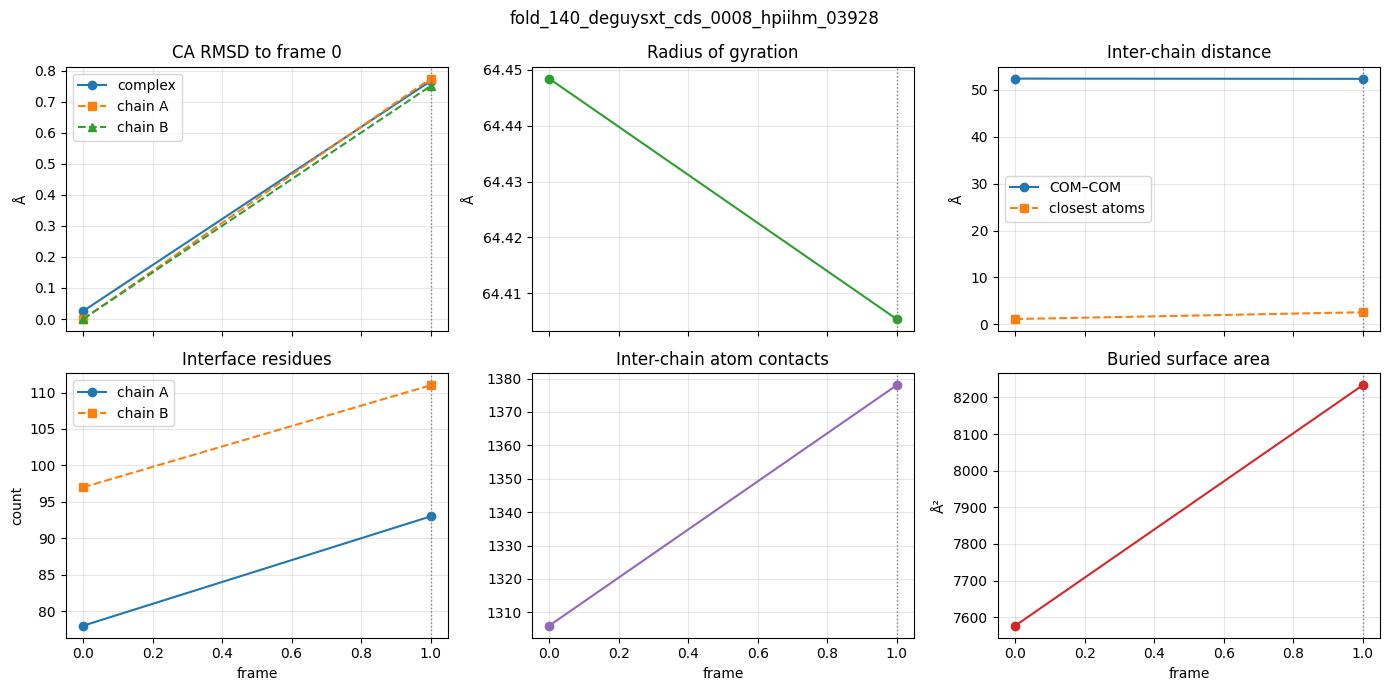

In [6]:
df = frames_df[frames_df["prediction_id"] == view_id].reset_index(drop=True)
fig = tv.plot_analysis(df, title=view_id)
print(tv.save_analysis(df, ANALYSIS_DIR, view_id, fig))
plt.show()

## 5. 3D animation (py3Dmol)

Chains are coloured (A blue, B red); residues of the interface (≤ `INTERFACE_CUTOFF_A`
in the last frame) are drawn as sticks. Frames are superposed on frame 0 so the
molecule does not drift. Mouse: rotate, scroll to zoom.

In [7]:
view = tv.show_trajectory(
    traj,
    interface_cutoff_angstrom=INTERFACE_CUTOFF_A,
    interval_ms=ANIMATION_INTERVAL_MS,
)
view.show()

Output hidden; open in https://colab.research.google.com to view.

In [8]:
# Static comparison of the first and the last frame
pair = tv.show_grid([traj[0], traj[-1]], ["frame 0 (initial)", f"frame {traj.n_frames - 1}"], frame=0, columns=2)
pair.show()

Output hidden; open in https://colab.research.google.com to view.

## 6. Per-residue flexibility (MDAnalysis) and interface cross-check

RMSF uses the MD frames only (initial/minimized frames are skipped based on the
run settings). Runs with `md_steps = 0` are skipped automatically.

In [9]:
first_md = 2 if row["minimized"] else 1
n_md_frames = int(row["n_frames_expected"] or 0) - first_md
if int(row["md_steps"] or 0) > 0 and n_md_frames >= 3:
    rmsf = tv.rmsf_per_residue(row["topology_pdb"], row["dcd_path"], start=first_md)
    rmsf.to_csv(ANALYSIS_DIR / f"{view_id}_rmsf.csv", index=False)
    tv.plot_rmsf(rmsf, title=f"{view_id} — CA RMSF")
    plt.show()
else:
    print("Too few MD frames: RMSF skipped (run OpenMM with OPENMM_MD_STEPS > 0).")

# Interface residues: mdtraj/scipy vs MDAnalysis (independent implementations)
a = tv.interface_residue_ids(traj, -1, INTERFACE_CUTOFF_A)
b = tv.interface_residues_mda(row["topology_pdb"], row["dcd_path"], -1, INTERFACE_CUTOFF_A)
print("Interface residues (last frame)")
for chain in a:
    print(f"  chain {chain}: {len(a[chain])} residues  {a[chain]}")
print("Agreement mdtraj vs MDAnalysis:", a == b)

Too few MD frames: RMSF skipped (run OpenMM with OPENMM_MD_STEPS > 0).


Interface residues (last frame)
  chain A: 0 residues  []
  chain B: 0 residues  []
Agreement mdtraj vs MDAnalysis: True


## 7. Compare the selected trajectories (last frame, up to `GRID_MAX`)

In [10]:
trajs, titles = [], []
if len(selected) > GRID_MAX:
    print(f"Showing the first {GRID_MAX} of {len(selected)} selected samples (GRID_MAX).")
for _, r in selected.head(GRID_MAX).iterrows():
    try:
        trajs.append(tv.load_trajectory(r["dcd_path"], r["topology_pdb"]))
        titles.append(f"#{r['rank']} {r['prediction_id'][:24]}")
    except Exception as exc:
        print("skip", r["prediction_id"], exc)

grid = tv.show_grid(trajs, titles, frame=-1, columns=GRID_COLUMNS,
                    cell_width=320, cell_height=300,
                    interface_cutoff_angstrom=INTERFACE_CUTOFF_A)
grid.show()

Output hidden; open in https://colab.research.google.com to view.

## 8. Export for PyMOL / ChimeraX / VMD

In [ ]:
out = tv.export_multimodel_pdb(traj, ANALYSIS_DIR / f"{view_id}_frames.pdb")
print("Multi-model PDB:", out)
print("Analysis folder:", ANALYSIS_DIR)

Multi-model PDB: /content/drive/MyDrive/MD_output_openmm/analysis/fold_121_deguysxt_cds_0008_hpiihm_01919_frames.pdb
Analysis folder: /content/drive/MyDrive/MD_output_openmm/analysis


## 9. Finalize

Copies the DCD + topology PDB of the selected samples to
`outputs/trajectories/` and marks the viewer stage as done.


In [ ]:
# ============================================================
# FINALIZE VIEWER: selected trajectories -> outputs/trajectories
# ============================================================
if "selected" not in globals():
    raise RuntimeError("Run section 2 (selection) first.")

traj_table = pl.collect_trajectories(L, selected)
n_ok = int(traj_table["dcd_path_copied"].sum())
print(f"Selected trajectories copied: {n_ok}/{len(traj_table)} -> {L.outputs_trajectories}")
if n_ok < len(traj_table):
    print("  missing:", traj_table.loc[~traj_table["dcd_path_copied"], "prediction_id"].tolist())

pl.mark_stage(L, "viewer", selected=len(selected), trajectories_copied=n_ok)
print("Stage 'viewer' marked done ->", L.status_file)
print("Status:", list(pl.read_status(L)))

## 10. Final candidate table (name, sequence, annotation)

Joins the selected samples with the `cross_pairs` JSON of `PBI_WGS_preprocess`
(`results/cross/<genome>/<ST>_<phage>_cross_pairs.json`) and writes one row per
selected candidate to `outputs/viewer/final_candidates_annotated.csv`:

| bacterial (OMP) | phage (RBP) |
|---|---|
| `bacterial_protein_id`, `bacterial_code` | `phage_protein_id`, `phage_code` |
| `bacterial_annotation` (Bakta description) | `phage_annotation` (`annot`) |
| `bacterial_sequence` (+ `sequence_type`, `length`) | `phage_sequence` (+ `length`) |
| `localization`, `tier`, `signalp`, `deeptmhmm2`, `n_support` | `rbpdetect_score`, `dpo_percent`, `sources`, `contig` |

plus the scores of the selection (`rank`, `haddock_score`, the OpenMM potentials)
and the trajectory paths.

The files are found automatically under
`PBI_WGS_preprocess/results/cross/` (only those whose path contains `DATASET`);
set `CROSS_PAIRS_FILES` in the cell to a list of full paths to override this.
The AF3 job name `<NNN>_<phage>__<bacterial>` is matched against the pairs on
alphanumerics only, so differences in case, `-`/`_` and a dropped `K-` genome
prefix do not matter. Rows that cannot be matched are kept with an empty
annotation and listed in the output.


In [ ]:
# ============================================================
# ANNOTATED CANDIDATE TABLE (name / sequence / annotation)
# ============================================================
# Joins the selected samples with the cross_pairs JSON of PBI_WGS_preprocess:
# one row per selected candidate = bacterial (OMP) protein + phage (RBP) protein.
import json as _json
import re as _re

# --- settings ---------------------------------------------------------------
CROSS_PAIRS_FILES  = None   # None: search below | or ["/content/drive/MyDrive/.../ST11_W10-2_cross_pairs.json"]
CROSS_PAIRS_ROOT   = DRIVE / "PBI_WGS_preprocess" / "results" / "cross"
CROSS_PAIRS_FILTER = DATASET  # only files whose path contains this (None = every file under the root)
ANNOTATED_CSV      = ANALYSIS_DIR / "final_candidates_annotated.csv"

if "selected" not in globals():
    raise RuntimeError("Run section 2 (selection) first.")

# --- 1. load the cross_pairs JSON(s) ----------------------------------------
if CROSS_PAIRS_FILES:
    _files = [Path(p) for p in CROSS_PAIRS_FILES]
else:
    _files = sorted(Path(CROSS_PAIRS_ROOT).glob("**/*cross_pairs*.json"))
    if CROSS_PAIRS_FILTER:
        _f = [p for p in _files if CROSS_PAIRS_FILTER.lower() in str(p).lower()]
        if _f:
            _files = _f
        elif _files:
            print(f"NOTE: no cross_pairs file mentions {CROSS_PAIRS_FILTER!r}; using all {len(_files)} file(s).")
_missing = [p for p in _files if not p.is_file()]
if _missing:
    raise FileNotFoundError("cross_pairs JSON not found: " + ", ".join(str(p) for p in _missing))
if not _files:
    raise FileNotFoundError(
        f"No *cross_pairs*.json under {CROSS_PAIRS_ROOT}.\n"
        "Set CROSS_PAIRS_FILES to the full path(s), e.g.\n"
        "  CROSS_PAIRS_FILES = ['/content/drive/MyDrive/PBI_WGS_preprocess/results/cross/"
        "bakta_KBN10P05309_ST11/ST11_W10-2_cross_pairs.json']"
    )

BACT, PHAGE, PAIRS = {}, {}, []
for _p in _files:
    _d = _json.loads(_p.read_text(encoding="utf-8"))
    for _k, _v in (_d.get("bacterial_proteins") or {}).items():
        BACT.setdefault(_k, dict(_v, cross_pairs_file=_p.name))
    for _k, _v in (_d.get("phage_proteins") or {}).items():
        PHAGE.setdefault(_k, dict(_v, cross_pairs_file=_p.name))
    for _pair in (_d.get("pairs") or []):
        PAIRS.append(dict(_pair, cross_pairs_file=_p.name))
    print(f"cross_pairs: {_p.name}: {len((_d.get('pairs') or []))} pairs, "
          f"{len(_d.get('bacterial_proteins') or {})} bacterial, {len(_d.get('phage_proteins') or {})} phage")
if not PAIRS:
    raise RuntimeError("The cross_pairs file(s) contain no 'pairs'.")
print(f"Total: {len(PAIRS)} pairs, {len(BACT)} bacterial, {len(PHAGE)} phage proteins")


# --- 2. match prediction_id -> pair -----------------------------------------
# AF3 job name = <NNN>_<phage protein>__<bacterial protein>, lower-cased and with
# '-'/'__' replaced in the fold folder name. Matching therefore compares
# alphanumerics only, and also accepts a phage id whose genome prefix (e.g. "K-")
# was dropped when the AF3 job was submitted.
def _norm(s):
    return _re.sub(r"[^a-z0-9]", "", str(s).lower())

_INDEX = {}
for _pair in PAIRS:
    _pair["_bn"] = _norm(_pair.get("bacterial"))
    _pair["_pn"] = _norm(_pair.get("phage"))
    _INDEX.setdefault(_pair["_pn"] + _pair["_bn"], _pair)


def match_pair(prediction_id):
    """(pair, how) for one prediction_id; (None, reason) when nothing matches."""
    tail = _re.sub(r"^fold_\d+_", "", str(prediction_id))
    tail = _re.sub(r"_(model_\d+|minimized|haddock_ready)$", "", tail)
    key = _norm(tail)
    if key in _INDEX:
        return _INDEX[key], "exact"
    hits = [p for p in PAIRS
            if key.endswith(p["_bn"]) and (key.startswith(p["_pn"]) or key.startswith(p["_pn"].lstrip("k")))]
    if len(hits) == 1:
        return hits[0], "normalized"
    if len(hits) > 1:
        return None, f"ambiguous ({len(hits)} pairs)"
    hits = [p for p in PAIRS if key.endswith(p["_bn"])]
    if len(hits) == 1:
        return hits[0], "bacterial id only"
    if len(hits) > 1:
        return None, f"ambiguous on the bacterial id ({len(hits)} pairs)"
    return None, "no pair with this phage/bacterial id"


# --- 3. one row per selected candidate --------------------------------------
_BACT_COLS = [("code", "bacterial_code"), ("genome", "bacterial_genome"),
              ("description", "bacterial_annotation"), ("localization", "bacterial_localization"),
              ("tier", "bacterial_tier"), ("signalp", "bacterial_signalp"),
              ("deeptmhmm2", "bacterial_deeptmhmm2"), ("n_support", "bacterial_n_support"),
              ("sequence_type", "bacterial_sequence_type"), ("length", "bacterial_length"),
              ("sequence", "bacterial_sequence")]
_PHAGE_COLS = [("code", "phage_code"), ("genome", "phage_genome"), ("contig", "phage_contig"),
               ("annot", "phage_annotation"), ("rbpdetect_score", "phage_rbpdetect_score"),
               ("dpo_percent", "phage_dpo_percent"), ("length", "phage_length"),
               ("sequence", "phage_sequence")]
_SCORES = ["rank", "haddock_score", "evdw", "eelec", "edesolv", "bsa",
           "initial_potential_kj_mol", "minimized_potential_kj_mol", "n_atoms",
           "dcd_path", "topology_pdb"]

rows, unmatched = [], []
for _r in selected.to_dict("records"):
    pid = str(_r["prediction_id"])
    pair, how = match_pair(pid)
    row = {"prediction_id": pid, "fold_id": _r.get("fold_id") or pid[:8],
           "dataset": DATASET, "match": how}
    row.update({c: _r.get(c) for c in _SCORES if c in _r})
    if pair is None:
        unmatched.append((pid, how))
    else:
        b, p = BACT.get(pair["bacterial"], {}), PHAGE.get(pair["phage"], {})
        row.update({
            "pair_id": pair.get("pair_id"),
            "cross_pairs_file": pair.get("cross_pairs_file"),
            "bacterial_protein_id": pair.get("bacterial"),
            "phage_protein_id": pair.get("phage"),
        })
        row.update({out: b.get(src) for src, out in _BACT_COLS})
        row.update({out: p.get(src) for src, out in _PHAGE_COLS})
        if "sources" in p:
            row["phage_sources"] = ";".join(map(str, p.get("sources") or []))
    rows.append(row)

annotated = pd.DataFrame(rows)
_front = ["rank", "prediction_id", "fold_id", "dataset", "pair_id",
          "bacterial_protein_id", "bacterial_code", "bacterial_annotation",
          "phage_protein_id", "phage_code", "phage_annotation"]
_order = [c for c in _front if c in annotated.columns] + \
         [c for c in annotated.columns if c not in _front]
annotated = annotated[_order]
if "rank" in annotated.columns:
    annotated = annotated.sort_values("rank")

ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
annotated.to_csv(ANNOTATED_CSV, index=False)

print(f"\nSelected candidates : {len(annotated)}")
print(f"Annotated           : {len(annotated) - len(unmatched)}")
if unmatched:
    print(f"Not matched         : {len(unmatched)}")
    for pid, why in unmatched[:20]:
        print(f"  - {pid}: {why}")
    print("  (check CROSS_PAIRS_FILES / CROSS_PAIRS_FILTER: the right genome pair must be loaded)")
print("Saved:", ANNOTATED_CSV)

_show = [c for c in ("rank", "prediction_id", "bacterial_protein_id", "bacterial_annotation",
                     "phage_protein_id", "phage_annotation", "haddock_score") if c in annotated.columns]
annotated[_show]


## 11. Clean up

Removes the intermediate folders (`work/`). It runs only when the pipeline
**and** viewer stages are marked done and the final files exist. Default is a
report only; set `CLEANUP_DELETE = True` to delete.

Kept: AF3 input, `modules/`, `charmm/`, `outputs/` (pipeline tables, viewer
analysis, annotated candidate table, selected trajectories). After cleanup,
re-running the notebooks recomputes every step.


In [ ]:
# ============================================================
# CLEANUP: remove intermediate folders
# ============================================================
CLEANUP_DELETE = False      # False: report only | True: delete (cannot be undone)

report = pl.cleanup_work(L, dry_run=not CLEANUP_DELETE)

print("Intermediate folders" + (" (to delete)" if report["dry_run"] else ""))
for p in report["plan"]:
    mark = "x" if p["exists"] else "-"
    print(f"  [{mark}] {p['path']}  {p['files']} files, {p['size']}")
print("Total:", report["total_size"])

if report["problems"]:
    print("\nNOT deleted:")
    for prob in report["problems"]:
        print("  -", prob)
elif report["dry_run"]:
    print("\nReport only. Set CLEANUP_DELETE = True and run this cell again to delete.")
else:
    print(f"\nDeleted {len(report['deleted'])} folders, freed {report['total_size']}.")
    print("Log:", L.outputs_dir / "cleanup_log.json")
    print("Kept:", L.outputs_dir)